In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (f1_score, accuracy_score, precision_score)
from sklearn.metrics import (recall_score, classification_report, confusion_matrix)
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score)

random_state = 42

In [2]:
cv_splits = 5

training_data = pd.read_csv("../dataset/task1_static/train_features.csv")
training_labels = pd.read_csv("../dataset/task1_static/train_labels.csv")
training_data = training_data.merge(training_labels, left_on="flow_id", right_on="flow_id")

validation_data = pd.read_csv("../dataset/task1_static/validation_features.csv")
validation_labels = pd.read_csv("../dataset/task1_static/validation_labels.csv")
validation_data = validation_data.merge(validation_labels, left_on="flow_id", right_on="flow_id")

In [3]:
selected_features = ['transport', 'start_rel', 'duration', 'server_port', 'packet_count_down', 'bytes_up', 'mean_pkt_size_up', 'mean_pkt_size_down', 
                     'std_pkt_size_up', 'std_pkt_size_down', 'mean_iat', 'std_iat', 'min_iat', 'max_iat', 'up_down_packet_ratio', 'up_down_byte_ratio']

low_association_features = ['std_pkt_size_down', 'up_down_byte_ratio', 'mean_iat',
                            'std_iat', 'min_iat', 'max_iat', 'server_port']

# set(selected_features) - set(low_assoiation_features)
reduced_features = [f for f in selected_features if f not in low_association_features]

# highly right-skewed features (skew > 1 in EDA), these go through log1p in E3/E4
skewed_features = ['min_iat', 'packet_count_down', 'up_down_byte_ratio', 'bytes_up', 'mean_iat',
                   'duration', 'std_iat', 'max_iat', 'mean_pkt_size_up']

# throughput style features (same as 10_google_youtube_confusion)
def add_rate_features(df):
    return df

training_data = add_rate_features(training_data)
validation_data = add_rate_features(validation_data)

X_train = training_data[selected_features].copy()
X_val = validation_data[selected_features].copy()

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(training_data["app"])
y_val = label_encoder.transform(validation_data["app"])

def preprocess_data(X, log_features=[]):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()
    log_cols = [c for c in numeric if c in log_features]
    numeric = [c for c in numeric if c not in log_features]
    numeric_pipe = Pipeline([('scaler', StandardScaler())])
    categorical_pipe = Pipeline([('onehot', OneHotEncoder())])
    log_pipe = Pipeline([('log', FunctionTransformer(np.log1p)), ('scaler', StandardScaler())])
    return ColumnTransformer([('numeric', numeric_pipe, numeric),
                              ('categorical', categorical_pipe, categorical),
                              ('log', log_pipe, log_cols)])

def report(search, Xtr, ytr, Xte, yte, experiment_name):
    start = time.time()
    search.fit(Xtr, ytr)
    elapsed = time.time() - start
    best_model = search.best_estimator_
    pred = best_model.predict(Xte)
    print("\n", experiment_name)
    print("Best CV macro-F1:", search.best_score_)
    print("Best parameters:", search.best_params_)
    print("Test macro-F1:", f1_score(yte, pred, average='macro'))
    print("Test accuracy:", accuracy_score(yte, pred))
    print(classification_report(yte, pred, zero_division=0))
    cm = confusion_matrix(yte, pred, labels=best_model.classes_)
    plt.figure(figsize=(10,8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=best_model.classes_, yticklabels=best_model.classes_)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion Matrix - {experiment_name}')
    plt.tight_layout(); plt.show()
    results = pd.DataFrame(search.cv_results_)
    results['experiment'] = experiment_name
    results['elapsed_seconds_search'] = elapsed
    results.to_csv(f'{experiment_name.lower().replace(" ", "_")}_all_cv_results.csv', index=False)
    return search, results, pred

def run_experiment(model, param_grid, model_name, feature_list, log_features=[], tag=None):
    Xtr, Xte = X_train[feature_list].copy(), X_val[feature_list].copy()
    pipe = Pipeline([('preprocess', preprocess_data(Xtr, log_features)), ('model', model)])
    grid = {'model__' + k: v for k, v in param_grid.items()}
    search = GridSearchCV(pipe, grid, scoring='f1_macro', cv=cv, n_jobs=-1, refit=True, return_train_score=True, verbose=1)
    if tag is None:
        tag = '_E1_16features' if len(feature_list)==16 else '_E2_reduced'
    experiment_name = model_name + tag
    return report(search, Xtr, y_train, Xte, y_val, experiment_name)

def evaluate(model, Xte, yte):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)
    return {"Accuracy": accuracy_score(yte, pred),
            "Balanced_Accuracy": balanced_accuracy_score(yte, pred),
            "F1_weighted": f1_score(yte, pred, average='weighted'),
            "Macro_F1": f1_score(yte, pred, average='macro'),
            "AUC_ROC": roc_auc_score(yte, proba, multi_class='ovr')}

## Model and tuning space

In [4]:
cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=random_state)
param_grid = {
    'C': [0.1, 1, 10, 100], 
    'kernel': ['linear', 'rbf'], 
    'gamma': ['scale', 'auto'], 
    'class_weight': [None, 'balanced']
}

### Experiment-1: All 16 selected features

Fitting 5 folds for each of 32 candidates, totalling 160 fits


/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/l


 svm_E1_16features
Best CV macro-F1: 0.6081589512493706
Best parameters: {'model__C': 100, 'model__class_weight': None, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Test macro-F1: 0.685877085877086
Test accuracy: 0.8192771084337349
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.81      0.91      0.86        33
           2       0.80      0.80      0.80         5
           3       0.80      0.80      0.80        10
           4       0.89      0.89      0.89        18
           5       0.83      0.71      0.77        14

    accuracy                           0.82        83
   macro avg       0.69      0.69      0.69        83
weighted avg       0.80      0.82      0.81        83



/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


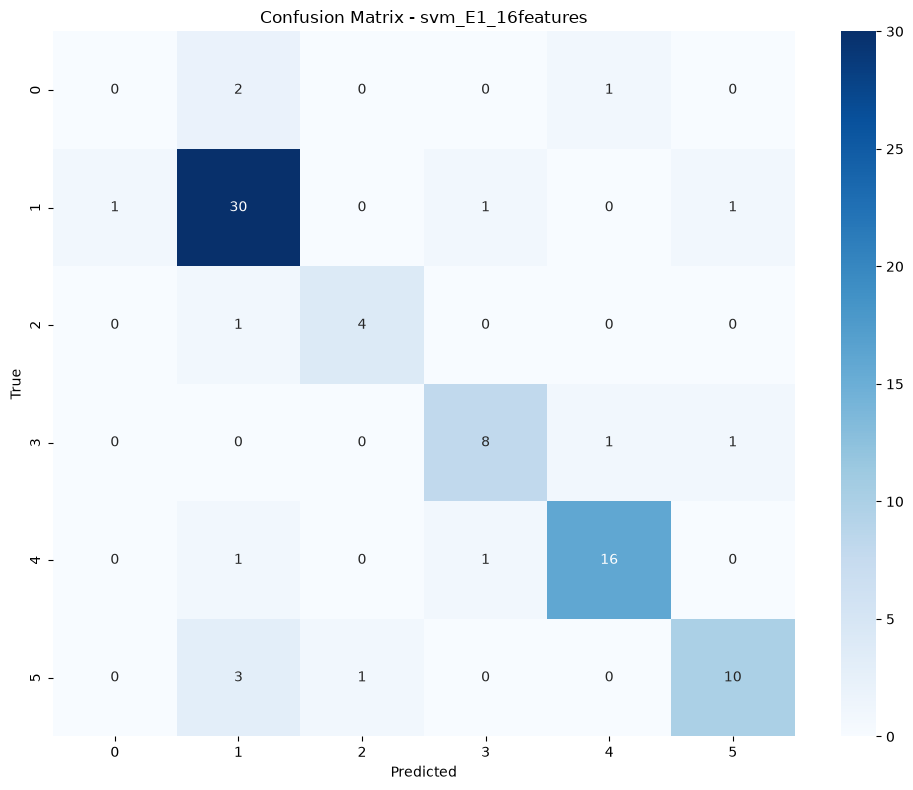

In [5]:
model_e1 = SVC(probability=True, random_state=random_state)
search_e1, results_e1, pred_e1 = run_experiment(model_e1, param_grid, 'svm', selected_features)

### Experiment-2: Reduced feature set (9 features)

/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/l

Fitting 5 folds for each of 32 candidates, totalling 160 fits


/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/l


 svm_E2_reduced
Best CV macro-F1: 0.5542565867565867
Best parameters: {'model__C': 100, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Test macro-F1: 0.6452300785634119
Test accuracy: 0.7590361445783133
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.88      0.88      0.88        33
           2       0.80      0.80      0.80         5
           3       0.67      1.00      0.80        10
           4       1.00      0.67      0.80        18
           5       0.62      0.57      0.59        14

    accuracy                           0.76        83
   macro avg       0.66      0.65      0.65        83
weighted avg       0.80      0.76      0.77        83



/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


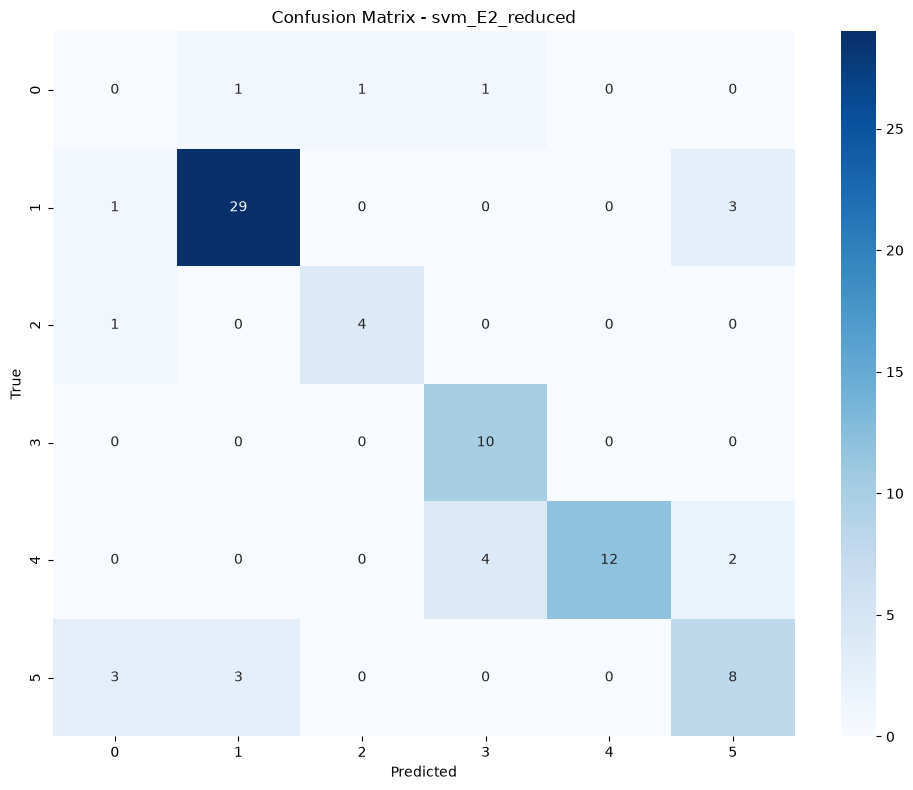

In [6]:
model_e2 = SVC(probability=True, random_state=random_state)
search_e2, results_e2, pred_e2 = run_experiment(model_e2, param_grid, 'svm', reduced_features)

### Experiment-3: Log-transform of the skewed features (16 features)

/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/l

Fitting 5 folds for each of 32 candidates, totalling 160 fits


/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/l


 svm_E3_log
Best CV macro-F1: 0.6266799752098684
Best parameters: {'model__C': 100, 'model__class_weight': None, 'model__gamma': 'auto', 'model__kernel': 'rbf'}
Test macro-F1: 0.7041933344238848
Test accuracy: 0.8313253012048193
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.81      0.88      0.84        33
           2       0.67      0.80      0.73         5
           3       1.00      0.90      0.95        10
           4       0.94      0.83      0.88        18
           5       0.80      0.86      0.83        14

    accuracy                           0.83        83
   macro avg       0.70      0.71      0.70        83
weighted avg       0.82      0.83      0.82        83



/home/user/Desktop/AI-For-Good-Challenge/tabfm_env311/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


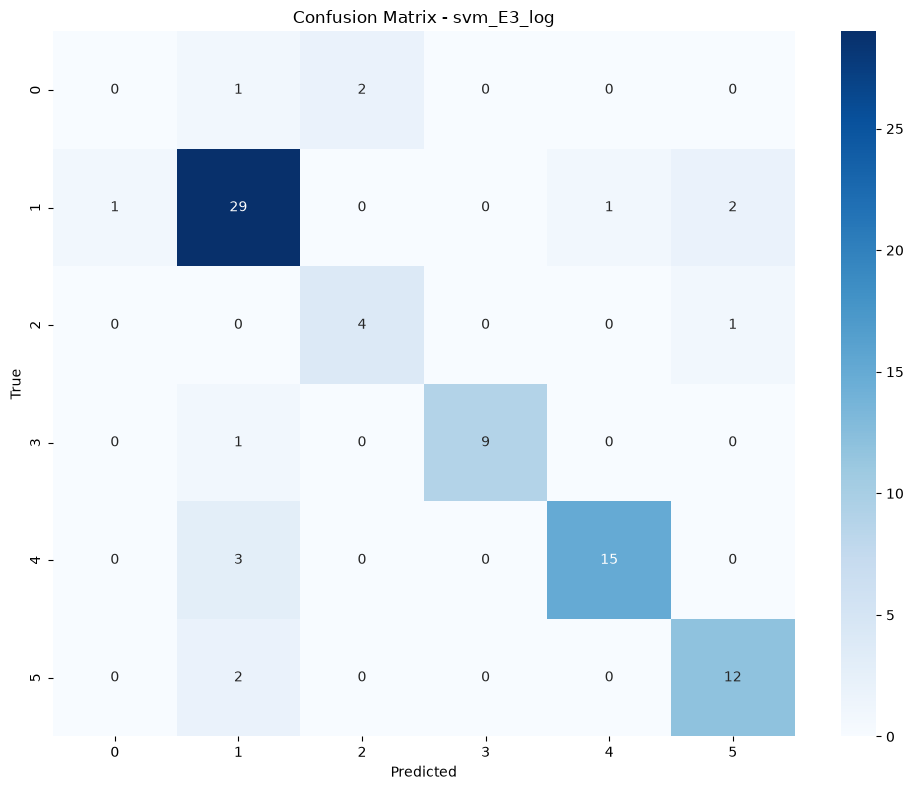

In [7]:
model_e3 = SVC(probability=True, random_state=random_state)
search_e3, results_e3, pred_e3 = run_experiment(model_e3, param_grid, 'svm', selected_features,
                                                log_features=skewed_features, tag='_E3_log')

### Compare feature configurations

In [8]:
experiments = {"E1_16feat": (search_e1, selected_features),
               "E2_reduced_feat": (search_e2, reduced_features),
               "E3_log": (search_e3, selected_features)}

comparision = []
for name, (search, feats) in experiments.items():
    row = {"Experiment": name, "Best_CV_MacroF1": search.best_score_}
    row.update(evaluate(search.best_estimator_, X_val[feats], y_val))
    comparision.append(row)
comparision = pd.DataFrame(comparision)
display(comparision.round(4))
comparision.to_csv('feature_ablation_comparison_svm.csv', index=False)

,Experiment,Best_CV_MacroF1,Accuracy,Balanced_Accuracy,F1_weighted,Macro_F1,AUC_ROC
0,E1_16feat,0.6082,0.8193,0.6854,0.8079,0.6859,0.9639
1,E2_reduced_feat,0.5543,0.7590,0.6528,0.7674,0.6452,0.9080
2,E3_log,0.6267,0.8313,0.7115,0.8231,0.7042,0.9760
